# Computer vision demo

How to use the `computer_vision` package:

| Module | What it does |
|---|---|
| `computer_vision/camera.py` | `Camera` opens the webcam and returns frames, `load_image` loads test images |
| `computer_vision/transform.py` | detects the ArUco markers and computes the camera → top-view transform |
| `computer_vision/position.py` | Thymio / goal pose (`get_position`, `marker_pose`), obstacles, `analyse_frame` |
| `computer_vision/visualization.py` | drawing helpers for the notebook |

Playground coordinates: `(0, 0)` = top-left corner of ArUco 0, `(1500, 1000)` = bottom-right corner of ArUco 2,
x to the right, y downwards. Angles are in radians, measured from +x towards +y (clockwise on screen).

In [1]:
%load_ext autoreload
%autoreload 2

import os
import matplotlib.pyplot as plt
import numpy as np

import computer_vision as vision

PLAYGROUND_FOLDER = os.path.join("img", "playground")

## 1. Load an image (or grab one from the camera)

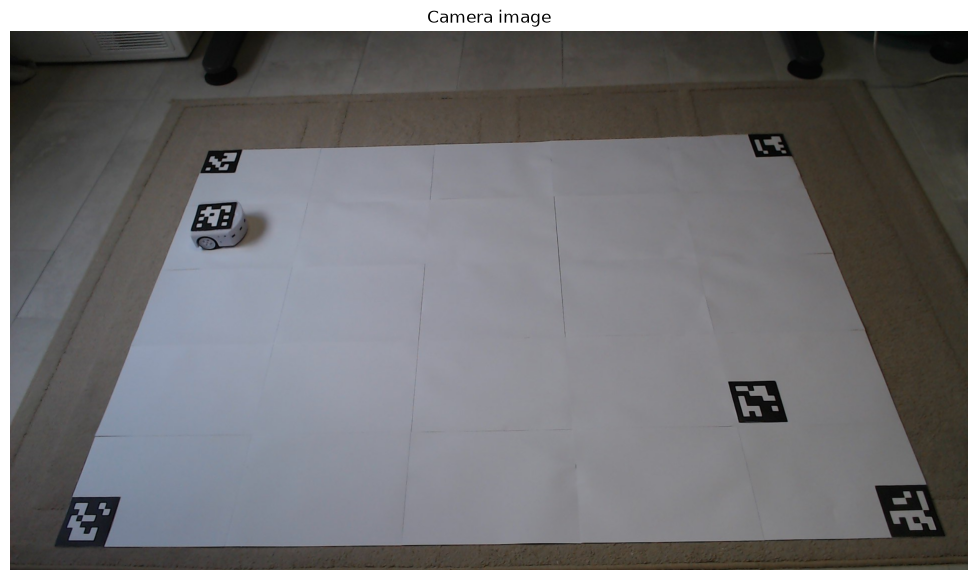

In [2]:
image = vision.load_image(os.path.join(PLAYGROUND_FOLDER, "aruco.jpg"))
# With a webcam instead:
# with vision.Camera(index=0) as camera:
#     image = camera.read()

vision.show(image, "Camera image")
plt.show()

## 2. Transform to a top view

`detect_markers` finds the ArUco markers in the camera image, `compute_transform` builds the
perspective transform from the four corner markers, `warp_playground` produces the top view.

Markers found: [0, 1, 2, 3, 4, 5]
Playground from (0, 0) to (1500, 1000)


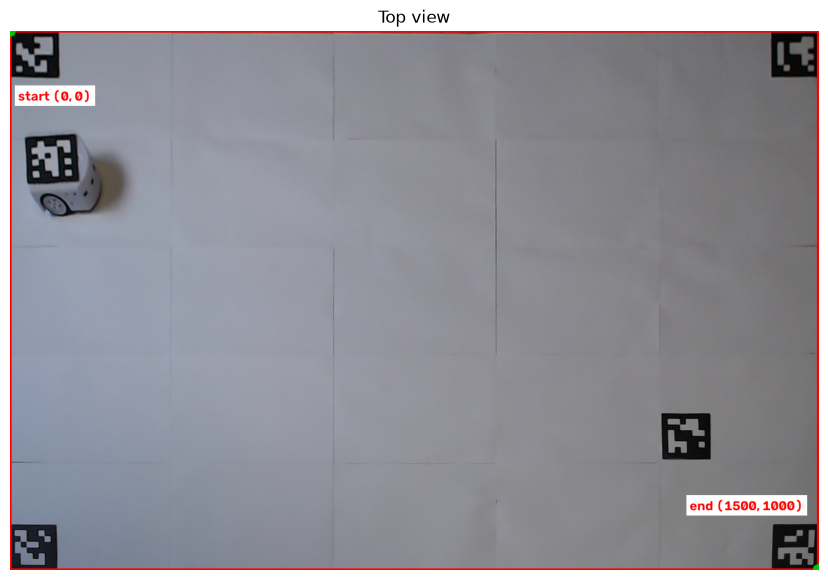

In [3]:
markers = vision.detect_markers(image)
print("Markers found:", sorted(markers))

transform = vision.compute_transform(markers)          # default size: vision.DEFAULT_SIZE = (1500, 1000)
top_view = vision.warp_playground(image, transform)

start, end = vision.playground_rectangle(markers, transform)
print("Playground from", start, "to", end)

outlined = top_view.copy()
vision.draw_playground_outline(outlined, start, end)
vision.show(outlined, "Top view")
plt.show()

## 3. Position of the Thymio (ArUco 4) and the goal (ArUco 5)

`get_position` returns `(x, y, theta)` in playground pixels, or `None` if the marker is not visible.
If the marker is already detected, `marker_pose(markers, transform, id)` avoids detecting twice.

Thymio: x = 78.1, y = 237.0, theta = -0.043 rad (-2.4 deg)
Goal: x = 1253.7, y = 751.4, theta = -1.589 rad (-91.1 deg)


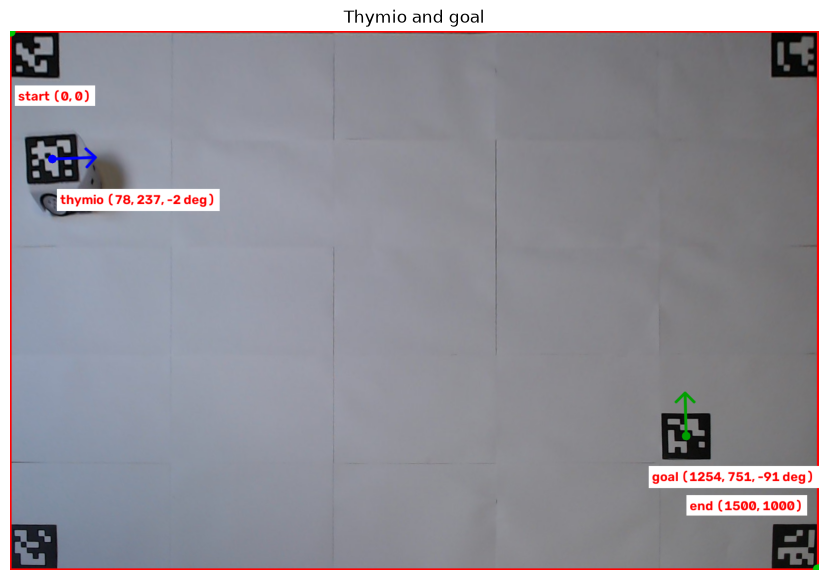

In [4]:
thymio = vision.get_position(image, transform, vision.THYMIO_ID)
goal = vision.marker_pose(markers, transform, vision.GOAL_ID)

for name, pose in [("Thymio", thymio), ("Goal", goal)]:
    if pose is None:
        print(f"{name}: not visible")
    else:
        x, y, theta = pose
        print(f"{name}: x = {x:.1f}, y = {y:.1f}, theta = {theta:.3f} rad ({np.degrees(theta):.1f} deg)")

posed = outlined.copy()
vision.draw_pose(posed, thymio, "thymio", vision.visualization.BLUE)
vision.draw_pose(posed, goal, "goal", vision.visualization.GREEN)
vision.show(posed, "Thymio and goal")
plt.show()

## 4. Full pipeline: obstacles + poses

`analyse_frame` does everything in one call and returns a `Frame` with
`warped`, `transform`, `thymio`, `goal`, `obstacles` (list of `Obstacle(corners, center, area)`) and `markers`.

=== 0_play.jpg ===
  Thymio: (68.49, 359.84, 0.05)
  Goal:   (1311.13, 713.68, -1.54)
  Obstacle 0: center = (373, 212), corners = [[381, 68], [501, 297], [365, 357], [246, 126]]
  Obstacle 1: center = (1336, 303), corners = [[1394, 169], [1488, 279], [1283, 435], [1183, 327]]
  Obstacle 2: center = (826, 534), corners = [[903, 407], [900, 661], [749, 661], [750, 408]]
  Obstacle 3: center = (553, 815), corners = [[626, 684], [708, 801], [480, 946], [395, 823]]
=== 1_play.jpg ===
  Thymio: (545.81, 472.63, -0.77)
  Goal:   (1311.76, 714.47, -1.54)
  Obstacle 0: center = (374, 213), corners = [[383, 70], [501, 298], [366, 358], [246, 127]]
  Obstacle 1: center = (1337, 304), corners = [[1394, 170], [1488, 280], [1283, 436], [1183, 329]]
  Obstacle 2: center = (826, 534), corners = [[903, 407], [901, 661], [749, 661], [751, 408]]
  Obstacle 3: center = (553, 816), corners = [[626, 684], [708, 802], [480, 946], [395, 823]]
=== 2_play.jpg ===
  Thymio: (886.13, 743.8, 0.9)
  Goal:   (1312.

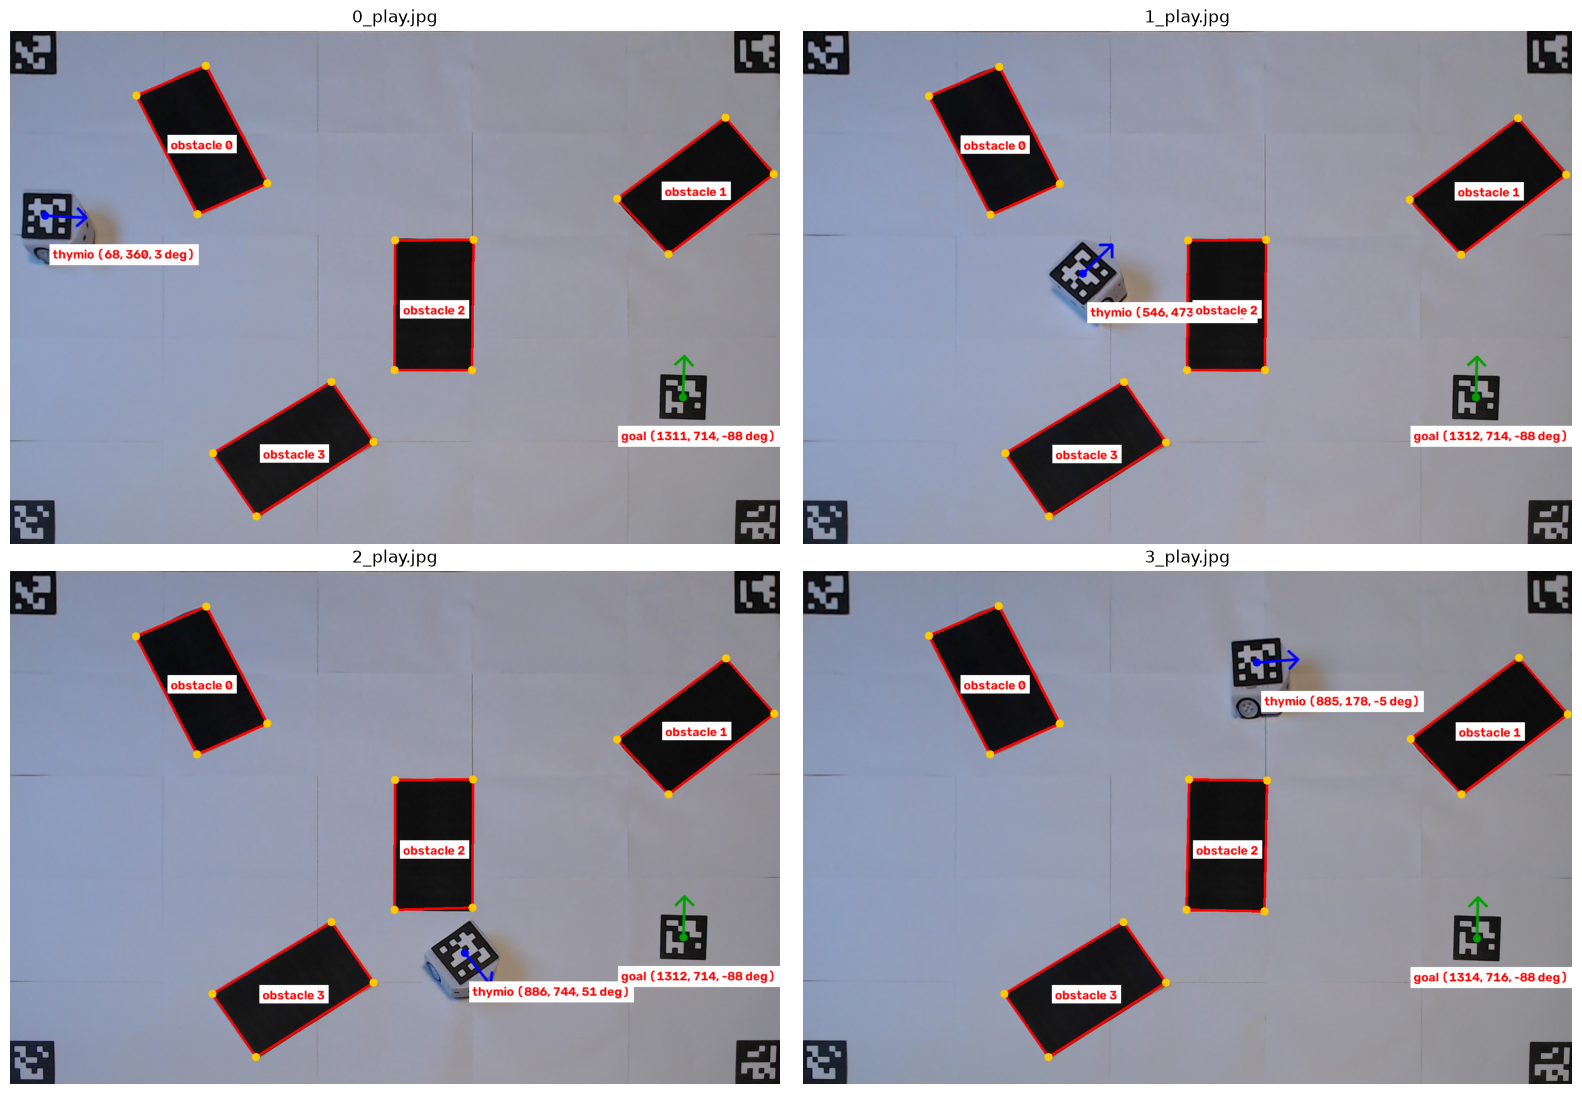

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
frames = {}
for index, ax in enumerate(axes.ravel()):
    name = f"{index}_play.jpg"
    frame = vision.analyse_frame(vision.load_image(os.path.join(PLAYGROUND_FOLDER, name)))
    frames[name] = frame

    print(f"=== {name} ===")
    print("  Thymio:", None if frame.thymio is None else tuple(round(v, 2) for v in frame.thymio))
    print("  Goal:  ", None if frame.goal is None else tuple(round(v, 2) for v in frame.goal))
    for i, obstacle in enumerate(frame.obstacles):
        print(f"  Obstacle {i}: center = ({obstacle.center[0]:.0f}, {obstacle.center[1]:.0f}), "
              f"corners = {obstacle.corners.tolist()}")

    vision.show(vision.draw_frame(frame), name, ax=ax)

plt.tight_layout()
plt.show()

## 5. Live camera

Set `USE_CAMERA = True` to run the pipeline on the webcam (press `q` in the window to stop).
The obstacles normally do not move, so they are detected once at the start; the loop then only
tracks the Thymio. `previous_transform` keeps the last transform when a corner marker is
temporarily hidden.

In [6]:
USE_CAMERA = False
CAMERA_INDEX = 0

if USE_CAMERA:
    import cv2

    with vision.Camera(index=CAMERA_INDEX) as camera:
        print("Camera resolution:", camera.resolution)
        first = vision.analyse_frame(camera.read())
        obstacles = first.obstacles
        print(f"{len(obstacles)} obstacles, goal at {first.goal}")

        transform = first.transform
        while True:
            try:
                frame = vision.analyse_frame(camera.read(), previous_transform=transform, find_obstacles=False)
            except ValueError as error:          # corner markers not visible yet
                print(error)
                continue
            transform = frame.transform
            frame.obstacles = obstacles
            print("Thymio:", frame.thymio, end="\r")

            cv2.imshow("playground", vision.draw_frame(frame))
            if cv2.waitKey(1) & 0xFF == ord("q"):
                break
    cv2.destroyAllWindows()